In [14]:
from pathlib import Path
from urllib.request import urlretrieve

PROJECT = Path("/home/samuel-logan/uni/ENGG2112/lake-erie-forecast")
IMAGE_FOLDER = PROJECT / "data" / "raw" / "satellite"
IMAGE_FOLDER.mkdir(parents=True, exist_ok=True)

base_url = (
    "https://www.nodc.noaa.gov/archive/arc0243/0312614/1.1/"
    "data/0-data/HAB_GreatLakes_Monitoring/"
    "meris-cicyano-10day-composites/GreatLakes1km/"
)

filename = "ts_2002.0710_0719.L4.GL1.CIcyano.v2.MAXIMUM_10day.tif"
image_path = IMAGE_FOLDER / filename

if not image_path.exists():
    urlretrieve(base_url + filename, image_path)

print("Downloaded:", image_path)
print("File size:", image_path.stat().st_size, "bytes")

Downloaded: /home/samuel-logan/uni/ENGG2112/lake-erie-forecast/data/raw/satellite/ts_2002.0710_0719.L4.GL1.CIcyano.v2.MAXIMUM_10day.tif
File size: 87018 bytes


In [15]:
import rasterio
import numpy as np
import pandas as pd

with rasterio.open(image_path) as src:
    print("Image dimensions:", src.width, "×", src.height)
    print("Number of bands:", src.count)
    print("Coordinate system:", src.crs)
    print("Missing-data value:", src.nodata)
    print("Band descriptions:", src.descriptions)
    print("Metadata:", src.tags())

    pixels = src.read(1)

values, counts = np.unique(pixels, return_counts=True)

pixel_summary = pd.DataFrame({
    "pixel_value": values,
    "number_of_pixels": counts,
})

display(
    pixel_summary.sort_values(
        "number_of_pixels", ascending=False
    ).head(15)
)

Image dimensions: 1206 × 835
Number of bands: 1
Coordinate system: PROJCS["Albers_Conic_Equal_Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",45.1],PARAMETER["longitude_of_center",-83.6],PARAMETER["standard_parallel_1",40.9],PARAMETER["standard_parallel_2",49.1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Missing-data value: 255.0
Band descriptions: ('Band_1',)
Metadata: {'DataType': 'Thematic', 'SAPS_product_created': '20231017T1225', 'SAPS_product_desc': 'RSTools (v3.0.5) timeseries composite created by cmd: arcpy.CreateTimeSeries (Input_file_selection_method="Workspace",Input_workspace="C:\\Users\\Travis.Briggs.NOS\\Documents\\cy

,pixel_value,number_of_pixels
225,252,783762
226,255,209943
41,42,245
39,40,244
42,43,231
53,54,231
40,41,226
45,46,222
49,50,217
36,37,216


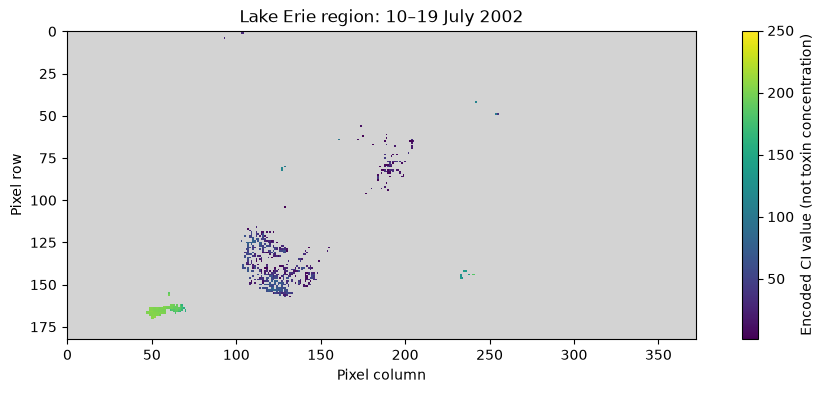

Crop dimensions: (183, 373)
Intensity pixels: 628
Land pixels: 45380
No-data pixels: 22251
Explicit no-detection pixels: 0


In [16]:
import matplotlib.pyplot as plt
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds

# Approximate bounding rectangle around Lake Erie.
# Order: west, south, east, north, in longitude/latitude.
erie_bounds = (-83.6, 41.3, -78.7, 43.0)

with rasterio.open(image_path) as src:
    # Convert longitude/latitude to this file's coordinate system.
    projected_bounds = transform_bounds(
        "EPSG:4326",
        src.crs,
        *erie_bounds,
        densify_pts=21,
    )

    window = from_bounds(
        *projected_bounds,
        transform=src.transform,
    ).round_offsets().round_lengths()

    erie_pixels = src.read(1, window=window)

# Separate intensity values from special flags.
intensity_mask = (erie_pixels >= 1) & (erie_pixels <= 250)

display_pixels = np.ma.masked_where(
    ~intensity_mask,
    erie_pixels,
)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(10, 4))

im = ax.imshow(
    display_pixels,
    cmap=cmap,
    vmin=1,
    vmax=250,
    interpolation="nearest",
)

ax.set_title("Lake Erie region: 10–19 July 2002")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

fig.colorbar(
    im,
    ax=ax,
    label="Encoded CI value (not toxin concentration)",
)

plt.tight_layout()
plt.show()

print("Crop dimensions:", erie_pixels.shape)
print("Intensity pixels:", int(intensity_mask.sum()))
print("Land pixels:", int((erie_pixels == 252).sum()))
print("No-data pixels:", int((erie_pixels == 255).sum()))
print("Explicit no-detection pixels:", int((erie_pixels == 0).sum()))

In [17]:
import re
from urllib.request import urlopen
import matplotlib.pyplot as plt

# Read the available filenames from NOAA's directory.
with urlopen(base_url, timeout=60) as response:
    listing = response.read().decode("utf-8")

available_files = sorted(set(
    re.findall(r'href="([^"]+\.tif)"', listing)
))

# Inspection samples only—not a rule for selecting training data.
sample_months = [
    (2002, 8),
    (2003, 7),
    (2005, 8),
    (2008, 9),
    (2011, 8),
]

selected_files = []

for year, month in sample_months:
    prefix = f"ts_{year}.{month:02d}"
    candidates = [
        name for name in available_files
        if name.startswith(prefix)
    ]

    if candidates:
        selected_files.append(candidates[0])
    else:
        print(f"No matching image found for {year}-{month:02d}")

if not selected_files:
    raise ValueError("No sample images found in the directory listing.")

fig, axes = plt.subplots(
    len(selected_files),
    1,
    figsize=(10, 3 * len(selected_files)),
    squeeze=False,
)

summary_rows = []

for ax, filename in zip(axes[:, 0], selected_files):
    path = IMAGE_FOLDER / filename

    if not path.exists():
        print("Downloading:", filename)
        urlretrieve(base_url + filename, path)

    with rasterio.open(path) as src:
        bounds = transform_bounds(
            "EPSG:4326",
            src.crs,
            *erie_bounds,
            densify_pts=21,
        )

        window = from_bounds(
            *bounds,
            transform=src.transform,
        ).round_offsets().round_lengths()

        crop = src.read(1, window=window)

    intensity = (crop >= 1) & (crop <= 250)
    land = crop == 252
    non_land_count = int((~land).sum())

    summary_rows.append({
        "filename": filename,
        "intensity_pixels": int(intensity.sum()),
        "land_pixels": int(land.sum()),
        "no_data_pixels": int((crop == 255).sum()),
        "explicit_no_detection": int((crop == 0).sum()),
        "intensity_pct_of_non_land": (
            100 * intensity.sum() / non_land_count
            if non_land_count else float("nan")
        ),
    })

    shown = np.ma.masked_where(~intensity, crop)

    ax.imshow(
        shown,
        cmap=cmap,
        vmin=1,
        vmax=250,
        interpolation="nearest",
    )
    ax.set_title(filename.split(".L4")[0])
    ax.set_axis_off()

plt.tight_layout()
plt.show()

image_check = pd.DataFrame(summary_rows)
display(image_check.round(2))

TimeoutError: The read operation timed out

In [ ]:
from urllib.parse import urljoin, unquote
from html.parser import HTMLParser

ARCHIVE = (
    "https://www.nodc.noaa.gov/archive/arc0243/0312614/1.1/"
    "data/0-data/HAB_GreatLakes_Monitoring/"
)

sensor_folders = {
    "MERIS": "meris-cicyano-10day-composites/GreatLakes1km/",
    "MODIS": "modis-cyannet-cicyano-10day-composites/Lake_Erie/",
    "OLCI": "olci-cicyano-10day-composites/GLErie300m/",
}

class LinkParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            self.links.extend(
                value for key, value in attrs if key == "href"
            )

def find_tifs(folder_url):
    """Read directory listings only, following child folders."""
    with urlopen(folder_url, timeout=60) as response:
        parser = LinkParser()
        parser.feed(response.read().decode("utf-8"))

    found = []
    for link in parser.links:
        # Ignore sorting links, parent directories and external links.
        if link.startswith(("?", "/", ".", "http", "#")):
            continue

        url = urljoin(folder_url, link)

        if link.lower().endswith(".tif"):
            found.append(url)
        elif link.endswith("/"):
            found.extend(find_tifs(url))

    return found

catalogue_rows = []

for sensor, folder in sensor_folders.items():
    print("Checking:", sensor)

    for url in find_tifs(ARCHIVE + folder):
        filename = unquote(url.rsplit("/", 1)[-1])

        # Extract dates such as 2002.0710_0719.
        match = re.search(r"(\d{4})\.(\d{4})_(\d{4})", filename)
        if match is None:
            continue

        year, start_code, end_code = match.groups()
        start = pd.to_datetime(year + start_code, format="%Y%m%d")
        end = pd.to_datetime(year + end_code, format="%Y%m%d")

        if end < start:
            end = pd.to_datetime(
                str(int(year) + 1) + end_code,
                format="%Y%m%d",
            )

        if 2002 <= start.year <= 2019:
            catalogue_rows.append({
                "sensor": sensor,
                "image_start": start,
                "image_end": end,
                "filename": filename,
                "url": url,
            })

image_catalogue = (
    pd.DataFrame(catalogue_rows)
    .drop_duplicates("url")
    .sort_values(["sensor", "image_end", "filename"])
)

display(
    image_catalogue.groupby("sensor").agg(
        files=("filename", "size"),
        first_start=("image_start", "min"),
        last_end=("image_end", "max"),
    )
)

Checking: MERIS
Checking: MODIS


TimeoutError: The read operation timed out

In [ ]:
label_files = list(
    (PROJECT / "data" / "raw" / "ai_2023").rglob("*mmc3.xlsx")
)
if len(label_files) != 1:
    raise ValueError("Expected exactly one mmc3.xlsx file.")

image_targets = pd.read_excel(
    label_files[0], sheet_name="all", header=1
)

start_codes = (
    image_targets["period"].astype(str)
    .str.split("-").str[0].str.strip().str.zfill(4)
)

image_targets["period_start"] = pd.to_datetime(
    image_targets["year"].astype(int).astype(str) + start_codes,
    format="%Y%m%d",
)

image_targets = image_targets.sort_values("period_start")

coverage = pd.DataFrame({
    "year": image_targets["year"].to_numpy(),
    "period_start": image_targets["period_start"].to_numpy(),
})

for sensor in sensor_folders:
    # Dates alone are sufficient for this availability check.
    image_dates = (
        image_catalogue.loc[
            image_catalogue["sensor"].eq(sensor), ["image_end"]
        ]
        .drop_duplicates()
        .sort_values("image_end")
    )

    matched = pd.merge_asof(
        image_targets[["period_start"]],
        image_dates,
        left_on="period_start",
        right_on="image_end",
        direction="backward",
        allow_exact_matches=False,
        tolerance=pd.Timedelta(days=10),
    )

    coverage[sensor] = matched["image_end"].notna().to_numpy()

coverage["any_sensor"] = coverage[list(sensor_folders)].any(axis=1)

print("Eligible forecast periods by year:")
display(
    coverage.groupby("year")[
        ["MERIS", "MODIS", "OLCI", "any_sensor"]
    ].sum()
)

print(
    "Periods with at least one eligible image:",
    int(coverage["any_sensor"].sum()),
    "of", len(coverage),
)

Eligible forecast periods by year:


,MERIS,MODIS,OLCI,any_sensor
year,,,,
2002,15,13,0,15
2003,15,14,0,15
2004,15,13,0,15
2005,15,14,0,15
2006,9,9,0,9
2007,15,12,0,15
2008,15,14,0,15
2009,15,12,0,15
2010,14,12,0,14


Periods with at least one eligible image: 237 of 240


In [ ]:
targets = image_targets.copy()

targets["sensor"] = np.select(
    [
        targets["year"] <= 2011,
        targets["year"] <= 2018,
    ],
    ["MERIS", "MODIS"],
    default="OLCI",
)

# Check for multiple files covering the same dates.
duplicate_versions = image_catalogue.duplicated(
    ["sensor", "image_end"], keep=False
)

if duplicate_versions.any():
    display(
        image_catalogue.loc[
            duplicate_versions,
            ["sensor", "image_start", "image_end", "filename"],
        ]
    )
    raise ValueError(
        "Multiple files share an end date. "
        "Inspect these before choosing a product version."
    )

matched_parts = []

for sensor in sensor_folders:
    sensor_targets = targets.loc[
        targets["sensor"].eq(sensor)
    ].sort_values("period_start")

    sensor_images = image_catalogue.loc[
        image_catalogue["sensor"].eq(sensor),
        ["image_start", "image_end", "filename", "url"],
    ].sort_values("image_end")

    matched = pd.merge_asof(
        sensor_targets,
        sensor_images,
        left_on="period_start",
        right_on="image_end",
        direction="backward",
        allow_exact_matches=False,
        tolerance=pd.Timedelta(days=10),
    )

    matched_parts.append(matched)

image_matches = (
    pd.concat(matched_parts, ignore_index=True)
    .sort_values("period_start")
    .reset_index(drop=True)
)

image_matches["image_age_days"] = (
    image_matches["period_start"] - image_matches["image_end"]
).dt.days

image_matches["has_image"] = image_matches["url"].notna()

display(
    image_matches.groupby("sensor").agg(
        forecast_periods=("period_start", "size"),
        matched_images=("has_image", "sum"),
        minimum_age_days=("image_age_days", "min"),
        maximum_age_days=("image_age_days", "max"),
    )
)

print("\nPeriods without a matching image:")
display(
    image_matches.loc[
        ~image_matches["has_image"],
        ["year", "period", "sensor"],
    ]
)

,forecast_periods,matched_images,minimum_age_days,maximum_age_days
sensor,,,,
MERIS,142,142,2.0,3.0
MODIS,89,86,2.0,4.0
OLCI,9,9,2.0,4.0



Periods without a matching image:


,year,period,sensor
142,2012,601-610,MODIS
157,2013,601-610,MODIS
172,2014,601-610,MODIS


In [ ]:
sensor_samples = {}

for sensor in ["MODIS", "OLCI"]:
    sample = image_matches.loc[
        image_matches["sensor"].eq(sensor)
        & image_matches["has_image"]
    ].iloc[0]

    path = IMAGE_FOLDER / sample["filename"]

    if not path.exists():
        print("Downloading:", sample["filename"])
        urlretrieve(sample["url"], path)

    sensor_samples[sensor] = path

    with rasterio.open(path) as src:
        print(f"\n--- {sensor} ---")
        print("File:", path.name)
        print("Forecast start:", sample["period_start"].date())
        print(
            "Image period:",
            sample["image_start"].date(),
            "to",
            sample["image_end"].date(),
        )
        print("Dimensions:", src.width, "×", src.height)
        print("Bands:", src.count)
        print("Pixel size in coordinate-system units:", src.res)
        print("Coordinate system:", src.crs)
        print("Data type:", src.dtypes)
        print("No-data value:", src.nodata)

        print("\nRelevant metadata:")
        for key, value in src.tags().items():
            if any(term in key.lower() for term in [
                "flag", "scaling", "units", "name", "desc"
            ]):
                print(f"{key}: {value}")

        values, counts = np.unique(
            src.read(1), return_counts=True
        )

    display(
        pd.DataFrame({
            "pixel_value": values,
            "number_of_pixels": counts,
        })
        .sort_values("number_of_pixels", ascending=False)
        .head(12)
    )


--- MODIS ---
File: ts.Terra.CyanNet_2012.0530_0608.L4.GL1.8_Kd_corr.MAXIMUM_10day.tif
Forecast start: 2012-06-11
Image period: 2012-05-30 to 2012-06-08
Dimensions: 1206 × 835
Bands: 1
Pixel size in coordinate-system units: (1100.0, 1100.0)
Coordinate system: PROJCS["Albers_Conic_Equal_Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",45.1],PARAMETER["longitude_of_center",-83.6],PARAMETER["standard_parallel_1",40.9],PARAMETER["standard_parallel_2",49.1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Data type: ('uint8',)
No-data value: 255.0

Relevant metadata:


,pixel_value,number_of_pixels
201,252,783639
202,255,222123
157,171,21
103,117,20
152,166,18
131,145,17
159,173,17
137,151,15
87,101,15
100,114,14



--- OLCI ---
File: ts_2019.0620_0629.L4.LE3.CIcyano.v3.MAXIMUM_10day.tif
Forecast start: 2019-07-01
Image period: 2019-06-20 to 2019-06-29
Dimensions: 1377 × 639
Bands: 1
Pixel size in coordinate-system units: (300.0, 300.0)
Coordinate system: EPSG:32617
Data type: ('uint8',)
No-data value: 255.0

Relevant metadata:
SAPS_product_desc: RSTools (v3.0.5) timeseries composite created by cmd: arcpy.CreateTimeSeries (Input_file_selection_method="Workspace",Input_workspace="C:\Users\Travis.Briggs.NOS\Documents\cyan_net\olci\300m",Input_filename_filter="*.tif",Recursive_search="true",Input_filelist="",Which_band="1",Composite_Type="TimeRange",Start_date="1/1/2000",Period_duration__days_="10",Do_not_span_months="false",Combine_Years="false",Copy_landmask="true",Landmask_values="252",Statistic="MAXIMUM",Create_count="false",Output_filename_prefix="ts_",Output_filename_suffix="_10day",Output_workspace="C:\Users\Travis.Briggs.NOS\Documents\cyan_net\olci\300m\10_day_composites",Minimum_valid_data_

,pixel_value,number_of_pixels
194,252,572634
195,255,304697
169,183,50
159,173,47
170,184,47
172,186,46
174,188,44
149,163,43
152,166,41
153,167,41


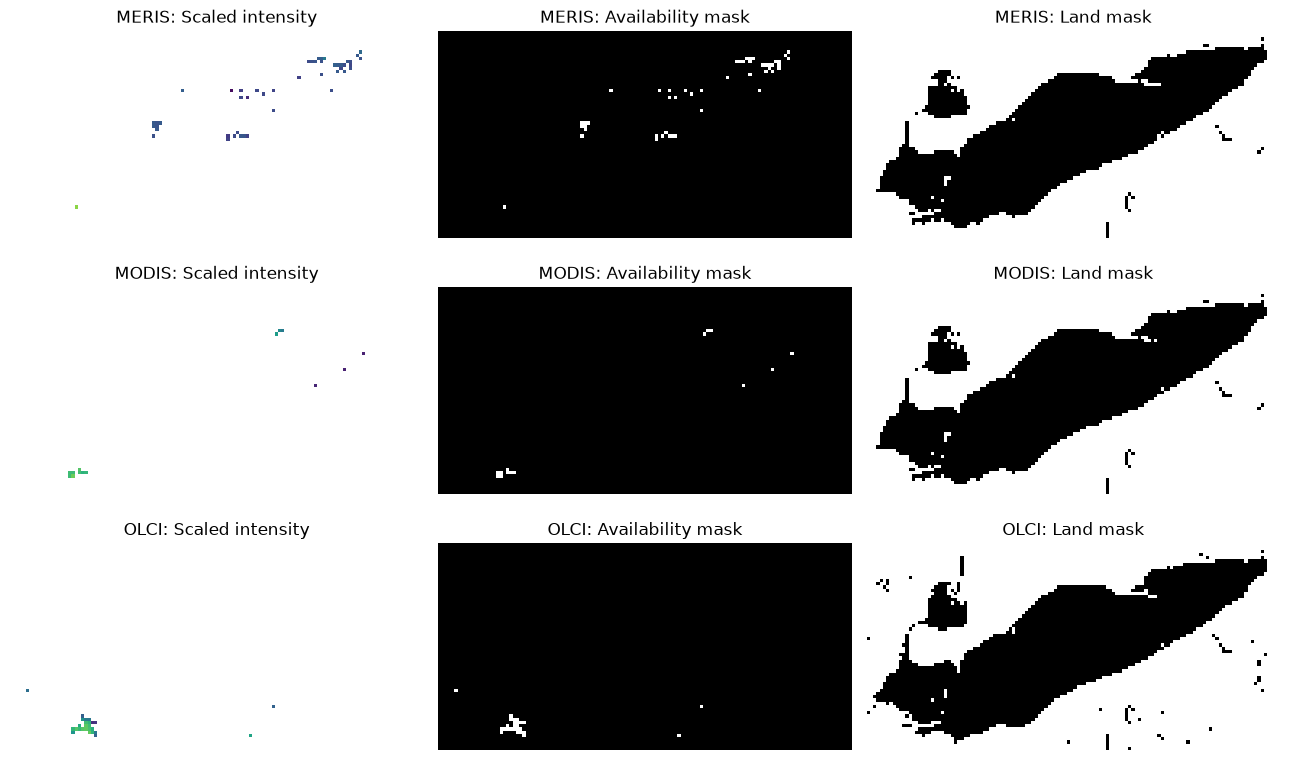

,sensor,shape,intensity_pixels,explicit_non_detection,available_pixels,land_pixels,other_or_unavailable_pixels
0,MERIS,"(3, 64, 128)",48,0,48,5248,2896
1,MODIS,"(3, 64, 128)",14,0,14,5245,2933
2,OLCI,"(3, 64, 128)",26,0,26,5212,2954


In [ ]:
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_bounds

# Agreed image size and the Lake Erie bounding box used earlier.
HEIGHT = 64
WIDTH = 128
ERIE_BOUNDS = (-83.6, 41.3, -78.7, 43.0)

# A shared longitude/latitude grid ensures that corresponding
# pixels represent the same geographic locations across sensors.
TARGET_CRS = "EPSG:4326"
TARGET_TRANSFORM = from_bounds(
    *ERIE_BOUNDS,
    width=WIDTH,
    height=HEIGHT,
)

def prepare_image(path):
    """Return a (3, 64, 128) array and the reprojected pixel codes."""

    # Areas outside the source image remain no-data.
    codes = np.full((HEIGHT, WIDTH), 255, dtype=np.uint8)

    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=codes,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=TARGET_TRANSFORM,
            dst_crs=TARGET_CRS,
            dst_nodata=255,
            resampling=Resampling.nearest,
        )

    intensity_pixels = (codes >= 1) & (codes <= 250)
    explicit_non_detection = codes == 0
    available = intensity_pixels | explicit_non_detection
    land = codes == 252

    intensity = np.zeros((HEIGHT, WIDTH), dtype=np.float32)
    intensity[intensity_pixels] = (
        codes[intensity_pixels].astype(np.float32) / 250.0
    )

    channels = np.stack([
        intensity,
        available.astype(np.float32),
        land.astype(np.float32),
    ])

    assert channels.shape == (3, HEIGHT, WIDTH)
    assert np.isfinite(channels).all()
    assert channels.min() >= 0 and channels.max() <= 1

    return channels, codes


prepared_samples = {}
summary_rows = []

fig, axes = plt.subplots(3, 3, figsize=(13, 8))

for row, sensor in enumerate(["MERIS", "MODIS", "OLCI"]):
    sample = image_matches.loc[
        image_matches["sensor"].eq(sensor)
        & image_matches["has_image"]
    ].iloc[0]

    # Check that the entire composite predates the forecast.
    assert sample["image_end"] < sample["period_start"]

    path = IMAGE_FOLDER / sample["filename"]

    if not path.exists():
        print("Downloading:", path.name)
        urlretrieve(sample["url"], path)

    sensor_samples[sensor] = path
    channels, codes = prepare_image(path)
    prepared_samples[sensor] = channels

    summary_rows.append({
        "sensor": sensor,
        "shape": str(channels.shape),
        "intensity_pixels": int(
            ((codes >= 1) & (codes <= 250)).sum()
        ),
        "explicit_non_detection": int((codes == 0).sum()),
        "available_pixels": int(channels[1].sum()),
        "land_pixels": int(channels[2].sum()),
        "other_or_unavailable_pixels": int(
            ((channels[1] == 0) & (channels[2] == 0)).sum()
        ),
    })

    # Hide unavailable pixels in this display only.
    intensity_display = np.ma.masked_where(
        channels[1] == 0, channels[0]
    )

    axes[row, 0].imshow(
        intensity_display, cmap="viridis", vmin=0, vmax=1
    )
    axes[row, 1].imshow(
        channels[1], cmap="gray", vmin=0, vmax=1
    )
    axes[row, 2].imshow(
        channels[2], cmap="gray", vmin=0, vmax=1
    )

    for col, title in enumerate([
        "Scaled intensity",
        "Availability mask",
        "Land mask",
    ]):
        axes[row, col].set_title(f"{sensor}: {title}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary_rows))

In [ ]:
# Process all matched images using our existing prepare_image() function.

matched = (
    image_matches.loc[image_matches["has_image"]]
    .copy()
    .sort_values("period_start")
    .reset_index(drop=True)
)

# Keep the same chronological split as our classification experiment.
matched["split"] = np.select(
    [
        matched["period_start"].dt.year <= 2014,
        matched["period_start"].dt.year <= 2016,
    ],
    ["train", "validation"],
    default="test",
)

assert matched["period_start"].is_unique
assert (matched["image_end"] < matched["period_start"]).all()

IMAGE_FOLDER.mkdir(parents=True, exist_ok=True)

image_arrays = []
image_records = []
image_errors = []

for number, (_, row) in enumerate(matched.iterrows(), start=1):
    path = IMAGE_FOLDER / row["filename"]

    try:
        if not path.exists():
            # Download to a temporary file so interrupted downloads
            # do not leave an apparently complete TIFF.
            temporary_path = path.with_suffix(".tif.part")
            urlretrieve(row["url"], temporary_path)
            temporary_path.replace(path)

        channels, codes = prepare_image(path)

        intensity_count = int(
            ((codes >= 1) & (codes <= 250)).sum()
        )
        non_land_count = int((codes != 252).sum())

        record = row.to_dict()
        record.update({
            # This index links the record to its array in X_images.
            "array_index": len(image_arrays),
            "local_path": str(path),
            "intensity_pixels": intensity_count,
            "available_pixels": int(channels[1].sum()),
            "land_pixels": int(channels[2].sum()),
            "explicit_non_detection": int((codes == 0).sum()),
            "intensity_pct_of_non_land": (
                100 * intensity_count / non_land_count
                if non_land_count else np.nan
            ),
            "zero_intensity": intensity_count == 0,
        })

        image_arrays.append(channels)
        image_records.append(record)

    except Exception as error:
        image_errors.append({
            "period_start": row["period_start"],
            "sensor": row["sensor"],
            "filename": row["filename"],
            "error": str(error),
        })
        print(f"Could not process: {row['filename']}")
        print(f"  {error}")

    if number % 25 == 0 or number == len(matched):
        print(f"Processed {number} of {len(matched)} matched periods")


if not image_arrays:
    raise RuntimeError("No images were successfully processed.")

X_images = np.stack(image_arrays).astype(np.float32)
image_manifest = pd.DataFrame(image_records)
image_error_table = pd.DataFrame(image_errors)

assert len(X_images) == len(image_manifest)
assert X_images.shape[1:] == (3, HEIGHT, WIDTH)

print("\nImage array shape:", X_images.shape)
print("Successfully processed:", len(image_manifest))
print("Processing errors:", len(image_errors))
print(
    "Periods without a matched image:",
    int((~image_matches["has_image"]).sum()),
)

coverage_summary = (
    image_manifest
    .groupby(["split", "sensor"])
    .agg(
        images=("intensity_pixels", "size"),
        zero_intensity_images=("zero_intensity", "sum"),
        minimum_intensity_pixels=("intensity_pixels", "min"),
        median_intensity_pixels=("intensity_pixels", "median"),
        maximum_intensity_pixels=("intensity_pixels", "max"),
        median_intensity_pct=(
            "intensity_pct_of_non_land", "median"
        ),
    )
    .round(2)
)

display(coverage_summary)

print("\nPeriods whose processed image has zero intensity pixels:")
display(
    image_manifest.loc[
        image_manifest["zero_intensity"],
        [
            "period_start",
            "sensor",
            "split",
            "available_pixels",
            "explicit_non_detection",
        ],
    ]
)

if image_errors:
    print("\nDownload or processing errors:")
    display(image_error_table)

Processed 25 of 237 matched periods
Processed 50 of 237 matched periods
Processed 75 of 237 matched periods
Processed 100 of 237 matched periods
Processed 125 of 237 matched periods
Processed 150 of 237 matched periods
Processed 175 of 237 matched periods
Processed 200 of 237 matched periods
Processed 225 of 237 matched periods
Processed 237 of 237 matched periods

Image array shape: (237, 3, 64, 128)
Successfully processed: 237
Processing errors: 0
Periods without a matched image: 3


images  zero_intensity_images  minimum_intensity_pixels  \
split      sensor                                                            
test       MODIS       22                      0                        13   
           OLCI         9                      0                        15   
train      MERIS      142                      1                         0   
           MODIS       42                      0                         4   
validation MODIS       22                      0                        20   

                   median_intensity_pixels  maximum_intensity_pixels  \
split      sensor                                                      
test       MODIS                      99.5                       387   
           OLCI                      134.0                       277   
train      MERIS                      53.5                       467   
           MODIS                      96.5                       492   
validation MODIS                     163.0                       695   

                   median_intensity_pct  
split      sensor                        
test       MODIS                   3.38  
           OLCI                    4.49  
train      MERIS                   1.82  
           MODIS                   3.27  
validation MODIS                   5.53


Periods whose processed image has zero intensity pixels:


,period_start,sensor,split,available_pixels,explicit_non_detection
1,2002-06-11,MERIS,train,0,0


In [ ]:
from pathlib import Path

PROJECT = Path(
    "/home/samuel-logan/uni/ENGG2112/lake-erie-forecast"
)
PROCESSED = PROJECT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

environment_features = [
    "flow_mean_10d",
    "rainfall_total_10d",
    "maumee_level_mean_10d",
    "detroit_level_mean_10d",
    "day_of_year",
]

environment_table = pd.read_csv(
    PROCESSED / "erie_environment_features.csv",
    parse_dates=["period_start"],
)

# Join by forecast date, retaining the image-array index.
paired_data = image_manifest.merge(
    environment_table.rename(
        columns={"significant_bloom": "target_label"}
    ),
    on="period_start",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert paired_data["_merge"].eq("both").all(), (
    "Some images have no matching environmental record."
)
assert paired_data[environment_features].notna().all().all(), (
    "Some environmental inputs are missing."
)
assert paired_data["target_label"].isin([0, 1]).all()

# Check agreement if the image manifest also contains the label.
if "significant_bloom" in paired_data.columns:
    assert paired_data["significant_bloom"].eq(
        paired_data["target_label"]
    ).all()

paired_data = (
    paired_data
    .drop(columns="_merge")
    .sort_values("array_index")
    .reset_index(drop=True)
)

assert np.array_equal(
    paired_data["array_index"].to_numpy(),
    np.arange(len(X_images)),
), "Image rows and table rows are not aligned."

# Save a reusable checkpoint.
np.savez_compressed(
    PROCESSED / "erie_images_64x128.npz",
    images=X_images,
)

paired_data.to_csv(
    PROCESSED / "erie_paired_data.csv",
    index=False,
)

print("Image array shape:", X_images.shape)
print("Paired examples:", len(paired_data))

display(
    paired_data.groupby("split").agg(
        examples=("target_label", "size"),
        significant_periods=("target_label", "sum"),
    )
)

Image array shape: (237, 3, 64, 128)
Paired examples: 237


,examples,significant_periods
split,,
test,31,10
train,184,32
validation,22,13


In [ ]:
%pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 6.9 MB/s eta 0:00:0000:0100:02m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 6.2 MB/s eta 0:00:0000:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 6.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 7.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 6.0 MB/s eta 0:00:0000:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 7.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 6.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 7.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 6.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 8.5 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━

In [ ]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)
print("CUDA GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
CUDA GPU available: False


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

PROJECT = Path(
    "/home/samuel-logan/uni/ENGG2112/lake-erie-forecast"
)
PROCESSED = PROJECT / "data" / "processed"

# Reload our saved checkpoint.
paired_data = pd.read_csv(
    PROCESSED / "erie_paired_data.csv",
    parse_dates=["period_start"],
)

with np.load(PROCESSED / "erie_images_64x128.npz") as saved:
    X_images = saved["images"]

environment_features = [
    "flow_mean_10d",
    "rainfall_total_10d",
    "maumee_level_mean_10d",
    "detroit_level_mean_10d",
    "day_of_year",
]

# Each row must point to its corresponding image.
paired_data = (
    paired_data.sort_values("array_index")
    .reset_index(drop=True)
)

assert len(paired_data) == len(X_images)
assert np.array_equal(
    paired_data["array_index"].to_numpy(),
    np.arange(len(X_images)),
)

X_environment = paired_data[
    environment_features
].to_numpy(dtype=np.float32)

y = paired_data["target_label"].to_numpy(dtype=np.int64)

split_masks = {
    split: paired_data["split"].eq(split).to_numpy()
    for split in ["train", "validation", "test"]
}

assert np.isfinite(X_environment).all()
assert np.isfinite(X_images).all()
assert np.isin(y, [0, 1]).all()

# Learn means and standard deviations from TRAINING inputs only.
scaler = StandardScaler()
scaler.fit(X_environment[split_masks["train"]])

# Apply that same transformation to every split.
X_environment_scaled = scaler.transform(
    X_environment
).astype(np.float32)

# Create one set of tensors for each split.
data_tensors = {}

for split, mask in split_masks.items():
    data_tensors[split] = {
        "environment": torch.from_numpy(
            X_environment_scaled[mask]
        ),
        "images": torch.from_numpy(X_images[mask]),
        "labels": torch.from_numpy(y[mask]),
    }

    print(f"\n{split.upper()}")
    for name, tensor in data_tensors[split].items():
        print(f"  {name}: {tuple(tensor.shape)}")

print("\nEnvironmental inputs:", environment_features)


TRAIN
  environment: (184, 5)
  images: (184, 3, 64, 128)
  labels: (184,)

VALIDATION
  environment: (22, 5)
  images: (22, 3, 64, 128)
  labels: (22,)

TEST
  environment: (31, 5)
  images: (31, 3, 64, 128)
  labels: (31,)

Environmental inputs: ['flow_mean_10d', 'rainfall_total_10d', 'maumee_level_mean_10d', 'detroit_level_mean_10d', 'day_of_year']


In [ ]:
from torch import nn

def make_environment_branch():
    return nn.Sequential(
        nn.Linear(5, 16),
        nn.ReLU(),
        nn.Linear(16, 8),
        nn.ReLU(),
    )


class EnvironmentalMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.environment_branch = make_environment_branch()

        self.classifier = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, 2),
        )

    def forward(self, environment):
        features = self.environment_branch(environment)
        return self.classifier(features)


class EnvironmentalCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.environment_branch = make_environment_branch()

        self.image_branch = nn.Sequential(
            # (3, 64, 128) → (8, 32, 64)
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # → (16, 16, 32)
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),

            # Convert the feature maps into 8 image features.
            nn.Linear(16 * 16 * 32, 8),
            nn.ReLU(),
        )

        self.classifier = nn.Sequential(
            # 8 environmental + 8 image features.
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2),
        )

    def forward(self, environment, images):
        environment_features = self.environment_branch(environment)
        image_features = self.image_branch(images)

        combined_features = torch.cat(
            [environment_features, image_features],
            dim=1,
        )

        return self.classifier(combined_features)


# Fix the random seed so initialisation is reproducible.
torch.manual_seed(42)

environment_model = EnvironmentalMLP()
combined_model = EnvironmentalCNN()

# Check a batch of four training examples.
sample_environment = data_tensors["train"]["environment"][:4]
sample_images = data_tensors["train"]["images"][:4]

with torch.no_grad():
    environment_output = environment_model(sample_environment)
    combined_output = combined_model(
        sample_environment, sample_images
    )

print("Environmental MLP output:", tuple(environment_output.shape))
print("Combined model output:", tuple(combined_output.shape))

for name, model in [
    ("Environmental MLP", environment_model),
    ("Combined MLP + CNN", combined_model),
]:
    parameters = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    print(f"{name}: {parameters:,} trainable parameters")

Environmental MLP output: (4, 2)
Combined model output: (4, 2)
Environmental MLP: 410 trainable parameters
Combined MLP + CNN: 67,474 trainable parameters


In [19]:
import copy
import time
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Training settings we agreed on.
BATCH_SIZE = 16
MAX_EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 0.001

train_data = data_tensors["train"]
validation_data = data_tensors["validation"]

# Compute class weights using training labels only.
class_counts = torch.bincount(
    train_data["labels"], minlength=2
).float()

class_weights = class_counts.sum() / (2 * class_counts)

print("Training class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())

criterion = nn.CrossEntropyLoss(weight=class_weights)


def get_scores(model, environment, images, use_images):
    if use_images:
        return model(environment, images)
    return model(environment)


def train_model(model, use_images, name, weight_decay=0.0):
    dataset = TensorDataset(
        train_data["environment"],
        train_data["images"],
        train_data["labels"],
    )

    # Use the same reproducible batch order for both models.
    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=weight_decay,
    )

    best_loss = float("inf")
    best_weights = None
    best_epoch = None
    epochs_without_improvement = 0
    records = []
    started = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()

        # Accumulate the weighted loss across all training batches.
        loss_numerator = 0.0
        loss_denominator = 0.0

        for environment, images, labels in loader:
            optimizer.zero_grad()

            scores = get_scores(
                model, environment, images, use_images
            )
            loss = criterion(scores, labels)

            loss.backward()
            optimizer.step()

            batch_weight = class_weights[labels].sum().item()
            loss_numerator += loss.item() * batch_weight
            loss_denominator += batch_weight

        training_loss = loss_numerator / loss_denominator

        # Validation is evaluated without updating any weights.
        model.eval()
        with torch.no_grad():
            validation_scores = get_scores(
                model,
                validation_data["environment"],
                validation_data["images"],
                use_images,
            )

            validation_loss = criterion(
                validation_scores,
                validation_data["labels"],
            ).item()

        if not np.isfinite([training_loss, validation_loss]).all():
            raise RuntimeError(f"{name}: non-finite loss encountered.")

        records.append({
            "epoch": epoch,
            "training_loss": training_loss,
            "validation_loss": validation_loss,
        })

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"{name} | epoch {epoch:3d} | "
                f"train {training_loss:.4f} | "
                f"validation {validation_loss:.4f}"
            )

        if epochs_without_improvement >= PATIENCE:
            print(f"{name}: early stopping at epoch {epoch}.")
            break

    model.load_state_dict(best_weights)
    model.eval()

    print(
        f"{name}: restored epoch {best_epoch}, "
        f"validation loss {best_loss:.4f}, "
        f"time {time.time() - started:.1f} seconds.\n"
    )

    return pd.DataFrame(records), best_epoch


# Reinitialise so rerunning this cell starts fresh.
torch.manual_seed(42)
environment_model = EnvironmentalMLP()

torch.manual_seed(42)
combined_model = EnvironmentalCNN()

environment_history, environment_best_epoch = train_model(
    environment_model,
    use_images=False,
    name="Environmental MLP",
)

combined_history, combined_best_epoch = train_model(
    combined_model,
    use_images=True,
    name="Environmental MLP + CNN",
)

Training class counts: [152.0, 32.0]
Class weights: [0.6052631735801697, 2.875]
Environmental MLP | epoch   1 | train 0.7031 | validation 0.6004
Environmental MLP | epoch  10 | train 0.6610 | validation 0.7789
Environmental MLP: early stopping at epoch 16.
Environmental MLP: restored epoch 1, validation loss 0.6004, time 0.4 seconds.

Environmental MLP + CNN | epoch   1 | train 0.6994 | validation 0.7259
Environmental MLP + CNN | epoch  10 | train 0.6825 | validation 0.7408
Environmental MLP + CNN | epoch  20 | train 0.4414 | validation 1.2852
Environmental MLP + CNN: early stopping at epoch 28.
Environmental MLP + CNN: restored epoch 13, validation loss 0.7169, time 3.3 seconds.



,model,examples,accuracy,precision,recall,F1,correct_warnings,false_alarms,missed_significant,correct_lower_severity
0,Environmental MLP,22,0.591,0.591,1.000,0.743,13,9,0,0
1,Environmental MLP + CNN,22,0.500,0.556,0.769,0.645,10,8,3,1


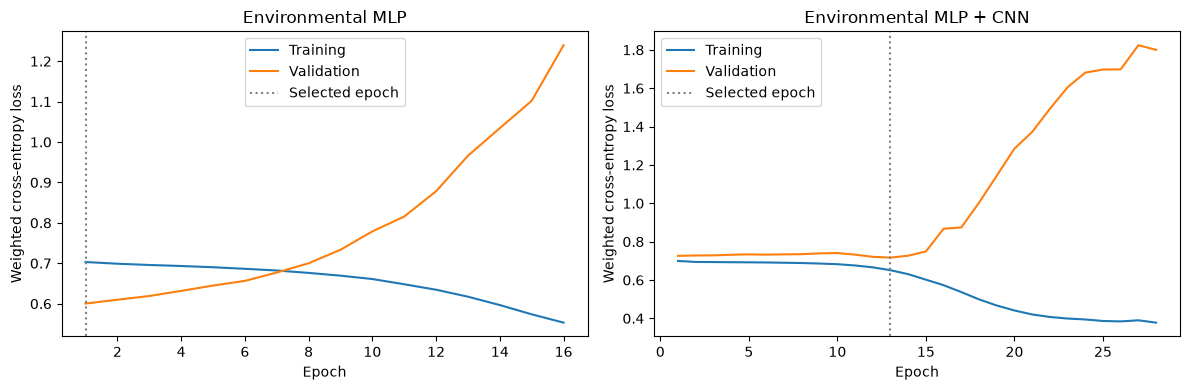

In [20]:
import matplotlib.pyplot as plt

validation_results = []
validation_predictions = {}

y_validation = validation_data["labels"].numpy()

for name, model, use_images in [
    ("Environmental MLP", environment_model, False),
    ("Environmental MLP + CNN", combined_model, True),
]:
    model.eval()

    with torch.no_grad():
        scores = get_scores(
            model,
            validation_data["environment"],
            validation_data["images"],
            use_images,
        )
        predictions = scores.argmax(dim=1).numpy()

    validation_predictions[name] = predictions

    tn, fp, fn, tp = confusion_matrix(
        y_validation, predictions, labels=[0, 1]
    ).ravel()

    validation_results.append({
        "model": name,
        "examples": len(y_validation),
        "accuracy": accuracy_score(y_validation, predictions),
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "correct_warnings": tp,
        "false_alarms": fp,
        "missed_significant": fn,
        "correct_lower_severity": tn,
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, history, name, best_epoch in [
    (
        axes[0], environment_history,
        "Environmental MLP", environment_best_epoch,
    ),
    (
        axes[1], combined_history,
        "Environmental MLP + CNN", combined_best_epoch,
    ),
]:
    ax.plot(
        history["epoch"], history["training_loss"],
        label="Training",
    )
    ax.plot(
        history["epoch"], history["validation_loss"],
        label="Validation",
    )
    ax.axvline(
        best_epoch, color="gray", linestyle=":",
        label="Selected epoch",
    )
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted cross-entropy loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [21]:
RESULTS = PROJECT / "results" / "neural_networks"
RESULTS.mkdir(parents=True, exist_ok=True)

validation_results.to_csv(
    RESULTS / "experiment_1_validation.csv", index=False
)
environment_history.to_csv(
    RESULTS / "experiment_1_environment_history.csv", index=False
)
combined_history.to_csv(
    RESULTS / "experiment_1_combined_history.csv", index=False
)

torch.save(
    {
        "environment_model": environment_model.state_dict(),
        "combined_model": combined_model.state_dict(),
        "environment_best_epoch": environment_best_epoch,
        "combined_best_epoch": combined_best_epoch,
        "environment_features": environment_features,
        "scaler_mean": scaler.mean_.tolist(),
        "scaler_scale": scaler.scale_.tolist(),
    },
    RESULTS / "experiment_1_models.pt",
)

print("Original experiment saved.")

Original experiment saved.


In [22]:
class SmallerEnvironmentalCNN(EnvironmentalCNN):
    def __init__(self):
        super().__init__()

        self.image_branch = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # (16, 16, 32) → (16, 4, 8)
            nn.AvgPool2d(kernel_size=4),

            nn.Flatten(),
            nn.Linear(16 * 4 * 8, 8),
            nn.ReLU(),
        )


WEIGHT_DECAY = 0.001

torch.manual_seed(42)
regularised_environment_model = EnvironmentalMLP()

torch.manual_seed(42)
smaller_combined_model = SmallerEnvironmentalCNN()

for name, model in [
    ("Regularised environmental MLP", regularised_environment_model),
    ("Smaller MLP + CNN", smaller_combined_model),
]:
    count = sum(p.numel() for p in model.parameters())
    print(f"{name}: {count:,} parameters")

regularised_environment_history, regularised_environment_best_epoch = (
    train_model(
        regularised_environment_model,
        use_images=False,
        name="Regularised environmental MLP",
        weight_decay=WEIGHT_DECAY,
    )
)

smaller_combined_history, smaller_combined_best_epoch = train_model(
    smaller_combined_model,
    use_images=True,
    name="Smaller MLP + CNN",
    weight_decay=WEIGHT_DECAY,
)

Regularised environmental MLP: 410 parameters
Smaller MLP + CNN: 6,034 parameters
Regularised environmental MLP | epoch   1 | train 0.7032 | validation 0.6004
Regularised environmental MLP | epoch  10 | train 0.6615 | validation 0.7409
Regularised environmental MLP: early stopping at epoch 16.
Regularised environmental MLP: restored epoch 1, validation loss 0.6004, time 0.2 seconds.

Smaller MLP + CNN | epoch   1 | train 0.6954 | validation 0.7295
Smaller MLP + CNN | epoch  10 | train 0.5735 | validation 0.4057
Smaller MLP + CNN | epoch  20 | train 0.2824 | validation 0.6470
Smaller MLP + CNN: early stopping at epoch 26.
Smaller MLP + CNN: restored epoch 11, validation loss 0.3787, time 2.6 seconds.



In [23]:
revision_rows = []
y_validation = validation_data["labels"].numpy()

for name, model, use_images in [
    (
        "Regularised environmental MLP",
        regularised_environment_model,
        False,
    ),
    ("Smaller MLP + CNN", smaller_combined_model, True),
]:
    model.eval()

    with torch.no_grad():
        scores = get_scores(
            model,
            validation_data["environment"],
            validation_data["images"],
            use_images,
        )
        predictions = scores.argmax(dim=1).numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_validation, predictions, labels=[0, 1]
    ).ravel()

    revision_rows.append({
        "model": name,
        "examples": len(y_validation),
        "accuracy": accuracy_score(y_validation, predictions),
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1": f1_score(y_validation, predictions, zero_division=0),
        "correct_warnings": tp,
        "false_alarms": fp,
        "missed_significant": fn,
        "correct_lower_severity": tn,
    })

revision_results = pd.DataFrame(revision_rows)

display(
    pd.concat(
        [validation_results, revision_results],
        ignore_index=True,
    ).round(3)
)

revision_results.to_csv(
    RESULTS / "experiment_2_validation.csv", index=False
)

,model,examples,accuracy,precision,recall,F1,correct_warnings,false_alarms,missed_significant,correct_lower_severity
0,Environmental MLP,22,0.591,0.591,1.000,0.743,13,9,0,0
1,Environmental MLP + CNN,22,0.500,0.556,0.769,0.645,10,8,3,1
2,Regularised environmental MLP,22,0.591,0.591,1.000,0.743,13,9,0,0
3,Smaller MLP + CNN,22,0.682,0.714,0.769,0.741,10,4,3,5


In [24]:
test_data = data_tensors["test"]
y_test = test_data["labels"].numpy()

test_predictions = {
    "Always lower severity": np.zeros_like(y_test),
    "Always significant": np.ones_like(y_test),
}

test_scores = {}

for name, model, use_images in [
    (
        "Regularised environmental MLP",
        regularised_environment_model,
        False,
    ),
    ("Smaller MLP + CNN", smaller_combined_model, True),
]:
    model.eval()

    with torch.no_grad():
        scores = get_scores(
            model,
            test_data["environment"],
            test_data["images"],
            use_images,
        )

        test_predictions[name] = scores.argmax(dim=1).numpy()

        # Model scores between 0 and 1; calibration is unverified.
        test_scores[name] = torch.softmax(
            scores, dim=1
        )[:, 1].numpy()


test_rows = []

for name, predictions in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    test_rows.append({
        "model": name,
        "examples": len(y_test),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "correct_warnings": tp,
        "false_alarms": fp,
        "missed_significant": fn,
        "correct_lower_severity": tn,
    })

neural_test_results = pd.DataFrame(test_rows)
display(neural_test_results.round(3))

# Preserve the date and prediction for each test example.
test_details = paired_data.loc[
    split_masks["test"],
    ["period_start", "sensor", "target_label"],
].copy()

for name, predictions in test_predictions.items():
    test_details[name] = predictions

for name, scores in test_scores.items():
    test_details[f"{name} — score"] = scores

neural_test_results.to_csv(
    RESULTS / "experiment_2_test_results.csv", index=False
)
test_details.to_csv(
    RESULTS / "experiment_2_test_predictions.csv", index=False
)

# Save the selected models and preprocessing information.
torch.save(
    {
        "environment_model": (
            regularised_environment_model.state_dict()
        ),
        "combined_model": smaller_combined_model.state_dict(),
        "environment_best_epoch": (
            regularised_environment_best_epoch
        ),
        "combined_best_epoch": smaller_combined_best_epoch,
        "environment_features": environment_features,
        "scaler_mean": scaler.mean_.tolist(),
        "scaler_scale": scaler.scale_.tolist(),
        "class_weights": class_weights.tolist(),
        "weight_decay": WEIGHT_DECAY,
        "image_shape": list(X_images.shape[1:]),
    },
    RESULTS / "experiment_2_models.pt",
)

print("Test results, predictions and model weights saved.")

,model,examples,accuracy,precision,recall,F1,correct_warnings,false_alarms,missed_significant,correct_lower_severity
0,Always lower severity,31,0.677,0.000,0.0,0.000,0,0,10,21
1,Always significant,31,0.323,0.323,1.0,0.488,10,21,0,0
2,Regularised environmental MLP,31,0.323,0.323,1.0,0.488,10,21,0,0
3,Smaller MLP + CNN,31,0.613,0.455,1.0,0.625,10,12,0,9


Test results, predictions and model weights saved.
